# Checks the processed data for DE_LU before running the full analysis pipeline

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd 
import matplotlib.pyplot as plt 
from data_pipeline import schema
from zone_settings import ROOT, get_zone

## Settings

In [2]:
ZONE = "DE_LU"
zone = get_zone(ZONE)
TZ = zone["timezone"]
DATA_PATH = ROOT / "data" / "processed" / f"{ZONE}.csv"
UK_PATH = ROOT / "data" / "market_impact_renewables.csv"
WINDOW_SIZE, STEP_SIZE = 10_000, 1_000 # as used in the DML scripts

## Load zone data

In [3]:
df = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)
schema.check_columns(df, zone["extra_controls"])
local = df.index.tz_convert(TZ)
print(df.shape)
print("From", local.min(), "to", local.max())

(61317, 15)
From 2019-01-01 00:00:00+01:00 to 2025-12-31 23:00:00+01:00


## Dropped hours

In [4]:
full = pd.date_range(zone["start"], zone["end"], freq="h", inclusive="left").tz_convert("UTC")
dropped = full.difference(df.index).tz_convert(TZ)
print(f"{len(dropped)} hours dropped")
print(pd.Series(1, index=dropped.date).groupby(level=0).size().rename("hours dropped").to_string())

51 hours dropped
2022-02-22    24
2022-03-24    24
2023-10-29     1
2024-10-27     1
2025-10-26     1


## Summary statistics

In [5]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price,61317.0,94.7,93.8,-500.0,37.7,74.0,114.9,936.3
load_forecast,61317.0,54676.4,9230.8,30893.1,47117.5,54512.2,62309.0,78154.4
wind_forecast,61317.0,14712.3,10759.3,244.6,6075.6,11884.7,21153.8,50447.0
solar_forecast,61317.0,6264.8,9695.0,0.0,0.0,240.1,9957.1,50917.7
wind_capacity,61317.0,65866.5,4908.8,59339.0,61907.0,64557.0,69533.0,76772.0
solar_capacity,61317.0,65670.0,16396.2,45435.0,51817.0,60684.0,79500.0,102606.0
gas_price,61317.0,45.1,44.7,3.5,16.1,32.7,47.2,339.2
co2_price,61317.0,57.7,24.0,14.6,28.0,65.9,78.4,97.5
wind_penetration,61317.0,27.4,20.1,0.4,11.2,22.3,39.1,127.3
solar_penetration,61317.0,10.8,17.0,0.0,0.0,0.4,16.7,103.4


## Value checks

In [6]:
show = {
    "negative price": (df[schema.PRICE]<0).sum(),
    "price at -500 floor": (df[schema.PRICE] <= -500).sum(),
    "price above 500": (df[schema.PRICE] > 500).sum(),
    "wind penetration > 100%": (df[schema.WIND_PENETRATION] > 100).sum(),
    "solar penetration > 100%": (df[schema.SOLAR_PENETRATION] > 100).sum()
}
must_be_zero = {
    "solar > 0 between 00:00 and 03:59": ((df[schema.SOLAR_FORECAST] > 0) & (df[schema.HOUR] <= 3)).sum(),
    "wind forecast > wind capacity": (df[schema.WIND_FORECAST] > df[schema.WIND_CAPACITY]).sum(),
    "solar forecast > solar capacity": (df[schema.SOLAR_FORECAST] > df[schema.SOLAR_CAPACITY]).sum(),
    "negative load or forecasts": (df[[schema.LOAD_FORECAST, schema.WIND_FORECAST, schema.SOLAR_FORECAST]] < 0).any(axis=1).sum()
}
print("To show (real, not errors):"); print(pd.Series(show).to_string())
print("\nMust be zero:"); print(pd.Series(must_be_zero).to_string())
print("\nHighest forecast / capacity: wind %.3f, solar %.3f" % (
    (df[schema.WIND_FORECAST] / df[schema.WIND_CAPACITY]).max(),
    (df[schema.SOLAR_FORECAST] / df[schema.SOLAR_CAPACITY]).max()))
print("\nHours with price above 500, by year:")
print((df[schema.PRICE] > 500).groupby(df[schema.YEAR]).sum().to_string())

To show (real, not errors):
negative price              2051
price at -500 floor            1
price above 500              530
wind penetration > 100%      113
solar penetration > 100%       2

Must be zero:
solar > 0 between 00:00 and 03:59    0
wind forecast > wind capacity        0
solar forecast > solar capacity      0
negative load or forecasts           0

Highest forecast / capacity: wind 0.775, solar 0.682

Hours with price above 500, by year:
year
2019      0
2020      0
2021     14
2022    499
2023      1
2024     15
2025      1


## Time-zone check (solar and price by hour)

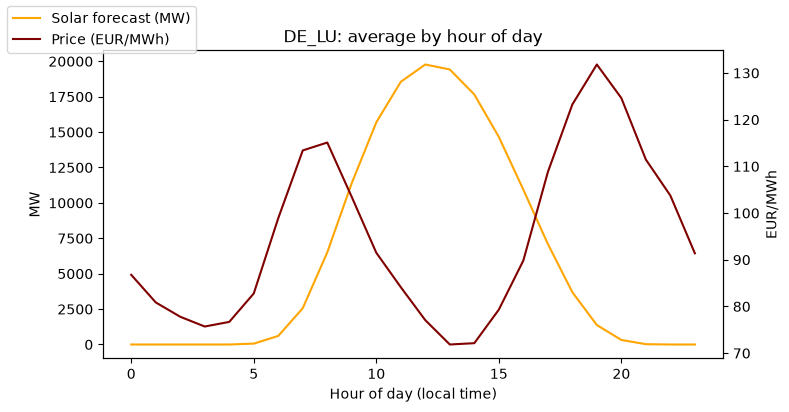

Solar peaks at hour 12


In [7]:
by_hour = df.groupby(schema.HOUR)
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(by_hour[schema.SOLAR_FORECAST].mean(), color="orange", label="Solar forecast (MW)")
ax1.set_xlabel("Hour of day (local time)")
ax1.set_ylabel("MW")
ax2 = ax1.twinx()
ax2.plot(by_hour[schema.PRICE].mean(), color="maroon", label="Price (EUR/MWh)")
ax2.set_ylabel("EUR/MWh")
fig.legend(loc="upper left")
ax1.set_title(f"{ZONE}: average by hour of day")
plt.show()
print("Solar peaks at hour", by_hour[schema.SOLAR_FORECAST].mean().idxmax())

## Annual averages of price, gas and carbon

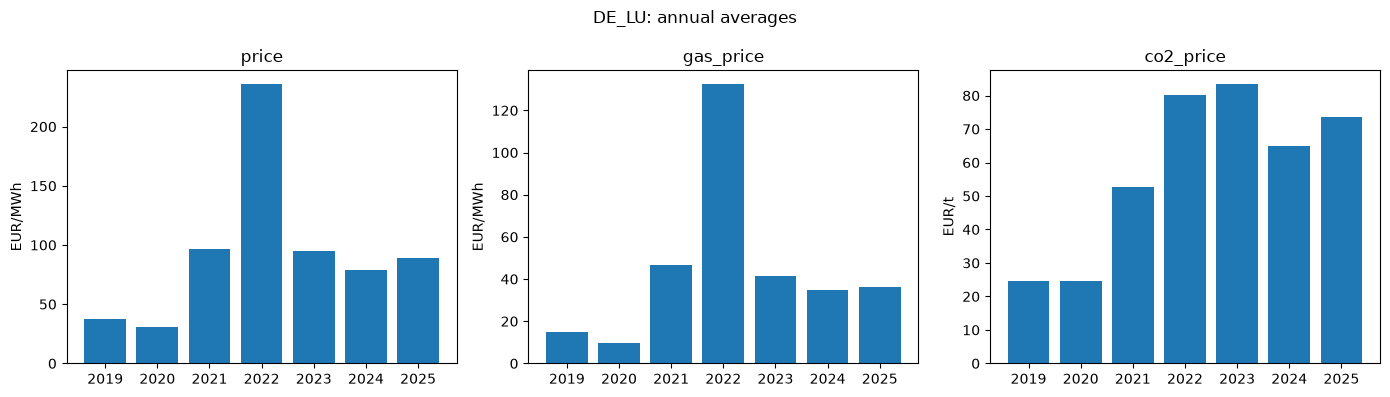

,price,gas_price,co2_price
year,,,
2019,38.0,15.0,25.0
2020,30.0,10.0,25.0
2021,97.0,47.0,53.0
2022,236.0,132.0,80.0
2023,95.0,42.0,83.0
2024,79.0,35.0,65.0
2025,89.0,36.0,73.0


In [8]:
by_year = df.groupby(schema.YEAR)[[schema.PRICE, schema.GAS_PRICE, schema.CO2_PRICE]].mean()
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col, unit in zip(axes, by_year.columns, ["EUR/MWh", "EUR/MWh", "EUR/t"]):
    ax.bar(by_year.index, by_year[col])
    ax.set_title(col)
    ax.set_ylabel(unit)
fig.suptitle(f"{ZONE}: annual averages")
plt.tight_layout()
plt.show()
by_year.round()

## Monthly forecasts and capacity

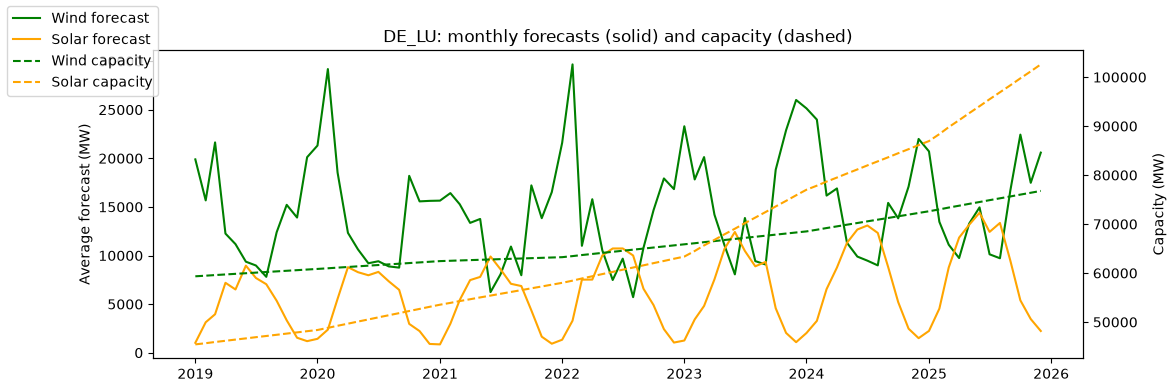

In [9]:
month = local.tz_localize(None).to_period("M")
monthly = df.groupby(month)[[schema.WIND_FORECAST, schema.SOLAR_FORECAST,
                             schema.WIND_CAPACITY, schema.SOLAR_CAPACITY]].mean()
monthly.index = monthly.index.to_timestamp()
fig, ax1 = plt.subplots(figsize=(12,4))
ax1.plot(monthly[schema.WIND_FORECAST], color="green", label="Wind forecast")
ax1.plot(monthly[schema.SOLAR_FORECAST], color="orange", label="Solar forecast")
ax1.set_ylabel("Average forecast (MW)")
ax2 = ax1.twinx()
ax2.plot(monthly[schema.WIND_CAPACITY], color="green", linestyle="--", label="Wind capacity")
ax2.plot(monthly[schema.SOLAR_CAPACITY], color="orange", linestyle="--", label="Solar capacity")
ax2.set_ylabel("Capacity (MW)")
fig.legend(loc="upper left")
ax1.set_title(f"{ZONE}: monthly forecasts (solid) and capacity (dashed)")
plt.show()

## Price against penetration

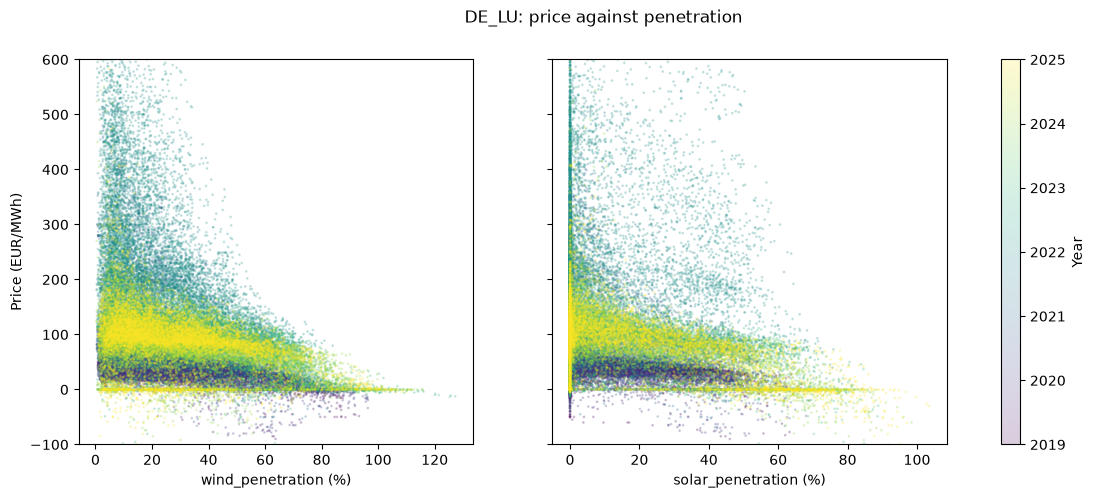

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, [schema.WIND_PENETRATION, schema.SOLAR_PENETRATION]):
    sc = ax.scatter(df[col], df[schema.PRICE], c=df[schema.YEAR], s=1, alpha=0.2, cmap="viridis")
    ax.set_xlabel(f"{col} (%)")
    ax.set_ylim(-100, 600)
axes[0].set_ylabel("Price (EUR/MWh)")
fig.colorbar(sc, ax=axes, label="Year")
fig.suptitle(f"{ZONE}: price against penetration")
plt.show()

## Comparison with the UK

In [11]:
uk = pd.read_csv(UK_PATH, usecols=["forecasted_wind_penetration", "forecasted_solar_penetration"]).rename(columns={
    "forecasted_wind_penetration": schema.WIND_PENETRATION,
    "forecasted_solar_penetration": schema.SOLAR_PENETRATION
})
quantiles = [0.1, 0.5, 0.9, 0.99, 1.0]
comparison = pd.DataFrame({
    f"{ZONE} wind": df[schema.WIND_PENETRATION].quantile(quantiles),
    "UK wind": uk[schema.WIND_PENETRATION].quantile(quantiles),
    f"{ZONE} solar": df[schema.SOLAR_PENETRATION].quantile(quantiles),
    "UK solar": uk[schema.SOLAR_PENETRATION].quantile(quantiles),
}).round(1)
print(comparison)
windows = lambda n: (n-WINDOW_SIZE) // STEP_SIZE + 1
print(f"\nRows: {ZONE} {len(df)}, UK {len(uk)}")
print(f"Sliding windows: {ZONE} {windows(len(df))}, UK {windows(len(uk))}")
print(f"Share of hours with solar penetration < 1%: {ZONE} {(df[schema.SOLAR_PENETRATION] < 1).mean():.1%}",
      f"UK {(uk[schema.SOLAR_PENETRATION] < 1).mean():.1%}")

      DE_LU wind  UK wind  DE_LU solar  UK solar
0.10         5.9      4.6          0.0       1.2
0.50        22.3     17.3          0.4       3.7
0.90        57.3     41.4         37.6       6.9
0.99        85.3     60.9         68.6       9.4
1.00       127.3     88.1        103.4      13.9

Rows: DE_LU 61317, UK 106096
Sliding windows: DE_LU 52, UK 97
Share of hours with solar penetration < 1%: DE_LU 52.4% UK 7.6%


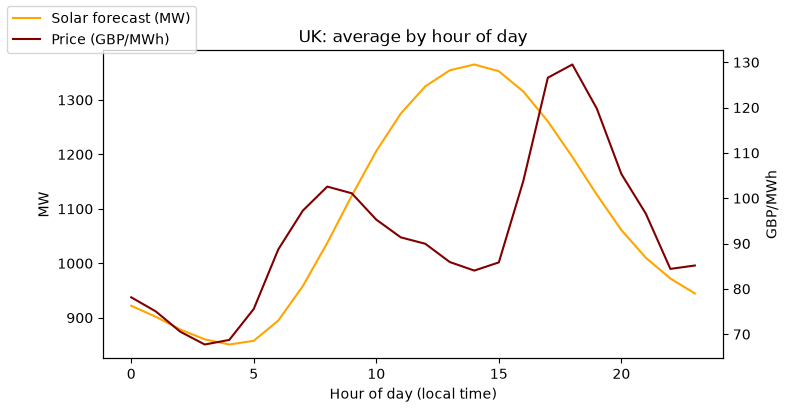

Solar peaks at hour 14


In [15]:
from analysis_settings import UK_COLUMNS

# UK data with the standard column names (UK_COLUMNS maps standard name -> UK name, so reversing it)
uk_full = pd.read_csv(UK_PATH, usecols=list(UK_COLUMNS.values())).rename(
    columns={uk_name: std_name for std_name, uk_name in UK_COLUMNS.items()})

by_hour_uk = uk_full.groupby(schema.HOUR)
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(by_hour_uk[schema.SOLAR_FORECAST].mean(), color="orange", label="Solar forecast (MW)")
ax1.set_xlabel("Hour of day (local time)")
ax1.set_ylabel("MW")
ax2 = ax1.twinx()
ax2.plot(by_hour_uk[schema.PRICE].mean(), color="maroon", label="Price (GBP/MWh)")
ax2.set_ylabel("GBP/MWh")
fig.legend(loc="upper left")
ax1.set_title("UK: average by hour of day")
plt.show()
print("Solar peaks at hour", by_hour_uk[schema.SOLAR_FORECAST].mean().idxmax())

## Findings

**Data checks (DE_LU):** All checks passed. The dataset has 61,317 hours (1 Jan 2019 to 31 Dec 2025); 51 hours were dropped because of missing load or wind/solar forecasts (22 Feb and 24 Mar 2022, plus the autumn clock-change hour in 2023 to 2025). Time zones are handled correctly (solar peaks at 12:00 local time), no forecast exceeds installed capacity, and there is no solar output at night. Negative prices (2,051 hours) and penetration above 100% (113 hours wind, 2 hours solar) are real market outcomes and are kept.

**Wind:** German wind penetration covers a wider range than the UK's (median 22.3% vs 17.3%, maximum 127.3% vs 88.1%), so the German curve extends beyond the UK one. The UK wind forecast behaves like a genuine hourly forecast (similar hour-to-hour behaviour to Germany's, and it follows ENTSO-E's GB day-ahead wind forecast on the days checked), so the wind comparison between the two countries is sound.

**Solar:** 52.4% of German hours have solar penetration below 1% (mostly night hours, with a solar forecast of zero). Sorted by penetration, the first ~20 of 52 sliding windows would contain only zero-solar hours, where no solar effect can be estimated. Decision: the German solar model uses only hours with a solar forecast above zero (35,187 hours, 26 windows); the wind model uses all hours.

**Issue with the UK data:** The UK `solar_forecast` column does not behave like an hourly solar forecast. It is never zero (minimum 2.3 MW, ~860 MW on average at 3:00), its daily pattern is far too flat, and it never exceeds about 22% of the stated capacity. On 21 June 2019 at 12:00, the UK file shows 1,702 MW (6.0% penetration), while ENTSO-E's official GB day-ahead solar forecast for that hour is 7,662 MW (about 27%). The paper does not discuss this. It explains its counter-intuitive solar results and the narrow solar range by confounding and low UK solar capacity. UK solar results should therefore not be compared directly with the German ones.

**To do (UK):** Re-source the GB day-ahead wind and solar forecasts, preferably from Elexon's DGWS/B1440 dataset (the same EU transparency item as the German ENTSO-E data; history back to 2018 still to be confirmed), or NESO's embedded wind and solar forecast archive (likely the paper's source). First step: swap the new forecasts into the existing UK file and rerun the UK analysis. Later: rebuild the UK as a full zone in the pipeline (price, load forecast, NBP gas, UK carbon price, GBP to EUR conversion).